# Bidirectional Reynolds ↔ acoustic-spectrum diagnostics

**Four analyses:** (1) grouped reverse-GRU frequency importance; (2) importance versus forward-LSTM signed residuals; (3) reverse-GRU cycle consistency on measured and reconstructed spectra; (4) compare current-Re versus Re-history forward models by ramps/plateaus.

**No model retraining for analyses 1–3.** Analysis 4 optionally fits *new benchmark* Ridge models, never modifies pretrained `.pt` files. No causal identification is claimed: these are held-out predictive diagnostics. Sign convention throughout: `actual − predicted`; positive = underprediction.

**Expected layout** (run this notebook from `project_root/notebooks/`): `../data/2026-03-04/`, `../models/`, `../results/`. Model checkpoints must be compatible with the supplied source architectures. Outputs go only to `../results/bidirectional_reynolds/`. If the forward checkpoint or a reliable healthy indicator is unavailable, analyses needing them fail clearly rather than producing misleading results.

In [4]:
from pathlib import Path
import re, json, warnings, random
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from IPython.display import display
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT=Path.cwd().resolve().parent if Path.cwd().name=='notebooks' else Path.cwd().resolve()
assert (ROOT/'data').exists() and (ROOT/'models').exists(), 'Run from project_root/notebooks or project root'
DATA_DIR=ROOT/'data'/'2026-03-04'; MODEL_DIR=ROOT/'models'; OUT=ROOT/'results'/'bidirectional_reynolds'; OUT.mkdir(parents=True,exist_ok=True)
assert DATA_DIR.is_dir(), f'Missing data folder: {DATA_DIR}'
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROBES=['UUS','US','DS','DDS']; W=40; S_SCALE=50.; RE_SCALE=150.
TRAIN_RUN='1211_1'; EVAL_RUN='1212_1'
# Supply checkpoint paths here if automatic discovery finds more than one candidate.
REVERSE_CHECKPOINT = "models/compact_gru_e16_h24_1211_to_1212.pt"
FORWARD_CHECKPOINT=None
# Must be verified from source dataset; if None, auto-detect exact leak event columns, otherwise fail closed.
LEAK_COLUMN=None
# Forward model probe coordinates taken from original GTvate_leak_detect notebook, for these two runs.
COORDS={'1211_1':{'UUS':[-3.0226,.025],'US':[-.4572,.025],'DS':[.4572,.025],'DDS':[3.0226,.025]},
        '1212_1':{'UUS':[-4.1275,.025],'US':[-.4572,.025],'DS':[.4572,.025],'DDS':[1.9177,.025]}}
print('Project:',ROOT,'\nData:',DATA_DIR,'\nModels:',MODEL_DIR,'\nResults:',OUT)
print('Checkpoints:',*[str(p.relative_to(ROOT)) for p in MODEL_DIR.rglob('*.pt')],sep='\n  ')

Project: /home/ubuntu/notebooks/Leak_Detection 
Data: /home/ubuntu/notebooks/Leak_Detection/data/2026-03-04 
Models: /home/ubuntu/notebooks/Leak_Detection/models 
Results: /home/ubuntu/notebooks/Leak_Detection/results/bidirectional_reynolds
Checkpoints:
  models/compact_gru_e16_h24_1211_to_1212.pt
  models/re_pred.pt
  models/leak_detect_baseline.pt
  models/compact_gru_e24_h16_1211_1_to_1212_1.pt
  models/leak_detect_residual.pt


## Data loading and strict alignment

Read the same four-probe frequency ordering and `/50` spectral scaling used by `spectral_to_reynolds(1).ipynb`. Require identical timestamps and Reynolds across probes (do **not** silently truncate misaligned records). Windows are built on original contiguous rows. A healthy endpoint must have **no leak anywhere in its 40-step input window**, preventing contamination in either model. Missing leak indicators are a hard error for healthy-only analyses.

In [5]:
def frequency_cols(df):
    pairs=[]
    for c in df.columns:
        if 'ǀf' in str(c):
            try: pairs.append((float(str(c).split('ǀf',1)[1].replace('_','.')),c))
            except ValueError: pass
    pairs.sort()
    if len(pairs)!=27: raise ValueError(f'Expected 27 frequencies; found {len(pairs)}')
    return [f for f,c in pairs],[c for f,c in pairs]
def sensor_csv(path):
    if not path.exists(): raise FileNotFoundError(path)
    d=pd.read_csv(path,sep=None,engine='python').dropna(how='all').dropna(axis=1,how='all')
    if d.shape[1]==1: d=pd.read_csv(path,sep='\t')
    return d.reset_index(drop=True)
def find_col(d,kind):
    if kind=='time':
        matches=[c for c in d if 'date' in str(c).lower() and 'time' in str(c).lower()]
    else:
        matches=[c for c in d if 'reynolds' in str(c).lower()]
    if not matches: raise KeyError(f'No {kind} column in {list(d.columns)}')
    return matches[0]
def read_run(run):
    dfs={p:sensor_csv(DATA_DIR/f'{p}{run}.csv') for p in PROBES}
    lengths={p:len(d) for p,d in dfs.items()}
    if len(set(lengths.values()))!=1: raise ValueError(f'Probe row-count mismatch: {lengths}')
    f0=None; X=[]; ref=None
    for p,d in dfs.items():
        freqs,cols=frequency_cols(d)
        if f0 is None: f0=freqs
        elif not np.allclose(f0,freqs): raise ValueError(f'Frequency order mismatch on {p}')
        t=pd.to_datetime(d[find_col(d,'time')],errors='raise').to_numpy()
        re_=pd.to_numeric(d[find_col(d,'re')],errors='raise').to_numpy(float)
        if ref is None: ref=(t,re_)
        elif not (np.array_equal(ref[0],t) and np.allclose(ref[1],re_,rtol=0,atol=1e-4)):
            raise ValueError(f'Timestamps/Reynolds not aligned for {p}')
        X.append(d[cols].apply(pd.to_numeric,errors='raise').to_numpy(np.float32))
    d=dfs[PROBES[0]]
    candidates=[c for c in d if re.search(r'leak.?event|leak.?open|leak.?status',str(c),re.I)]
    chosen=LEAK_COLUMN
    if chosen is None:
        if len(candidates)!=1: raise ValueError(f'Cannot establish healthy windows. Leak column candidates: {candidates}; set LEAK_COLUMN to a verified column')
        chosen=candidates[0]
    if chosen not in d: raise KeyError(f'Leak column {chosen!r} absent')
    leak=pd.to_numeric(d[chosen],errors='raise').to_numpy()
    if not np.isfinite(leak).all(): raise ValueError('Missing leak flags')
    return dict(X=np.stack(X,axis=1),Re=ref[1].astype(np.float32),time=ref[0],leak=leak,freqs=np.asarray(f0),run=run,leak_column=chosen)
train=read_run(TRAIN_RUN); val=read_run(EVAL_RUN)
assert np.allclose(train['freqs'],val['freqs'])
def endpoints(run):
    t=np.arange(W-1,len(run['Re']))
    # reject windows with leak anywhere, not only at endpoint
    leak_count=np.convolve((run['leak']!=0).astype(int),np.ones(W,dtype=int),'valid')
    return t[leak_count==0]
idx_train=endpoints(train); idx_val=endpoints(val)
if not len(idx_train) or not len(idx_val): raise ValueError('No healthy windows found')
print('Healthy windows: train',len(idx_train),'eval',len(idx_val),'leak column',val['leak_column'])
print('Frequency values:',val['freqs'])

Healthy windows: train 7567 eval 7567 leak column Leak Event
Frequency values: [   25.     31.5    40.     50.     63.     80.    100.    125.    160.
   200.    250.    315.    400.    500.    630.    800.   1000.   1250.
  1600.   2000.   2500.   3100.   4000.   5000.   6300.   8000.  10000. ]


## Load pretrained models (no retraining)

The reverse architecture below reproduces the compact GRU source: shared 27-frequency encoder, mean across probes, GRU over 40 steps, one Reynolds output. The forward architecture reproduces `BaselineSpectralModel` from `GTvate_leak_detect(2).ipynb`: Reynolds + coordinates → LSTM → 27 frequencies per probe. **Forward predictions are computed without using actual spectra as features**; the `X_window` argument supplies shape only. Checkpoint incompatibilities are reported rather than silently repaired.

In [6]:
class CompactSpectralGRU(nn.Module):
    def __init__(self,embed_dim,hidden_dim):
        super().__init__(); self.encoder=nn.Sequential(nn.Linear(27,embed_dim),nn.ReLU()); self.gru=nn.GRU(embed_dim,hidden_dim,batch_first=True); self.head=nn.Linear(hidden_dim,1)
    def forward(self,x):
        z=self.encoder(x).mean(dim=2); h,_=self.gru(z); return self.head(h[:,-1]).squeeze(-1)
class BaselineSpectralModel(nn.Module):
    def __init__(self,Freq=27,hidden_dim=64,re_feat_dim=16,coord_feat_dim=16):
        super().__init__(); self.Freq=Freq
        self.re_embed=nn.Sequential(nn.Linear(1,re_feat_dim),nn.ReLU())
        self.coord_embed=nn.Sequential(nn.Linear(2,coord_feat_dim),nn.ReLU())
        self.re_lstm=nn.LSTM(re_feat_dim+coord_feat_dim,hidden_dim,batch_first=True)
        self.re_to_spec=nn.Linear(hidden_dim,Freq)
    def forward(self,X_window,Re_window,coords):
        B,T,P,F=X_window.shape
        a=self.re_embed(Re_window[:,:,None,None].expand(-1,-1,P,1))
        c=self.coord_embed(coords[:,None].expand(-1,T,-1,-1))
        z=torch.cat([a,c],dim=-1).permute(0,2,1,3).reshape(B*P,T,-1)
        h,_=self.re_lstm(z)
        return {'baseline':self.re_to_spec(h.reshape(B,P,T,-1).permute(0,2,1,3))}
def choose_checkpoint(manual,pattern):
    if manual is not None:
        p=Path(manual); p=p if p.is_absolute() else ROOT/p
        if not p.is_file(): raise FileNotFoundError(p)
        return p
    found=sorted(MODEL_DIR.rglob(pattern))
    if len(found)!=1: raise ValueError(f'Expected one {pattern} in {MODEL_DIR}; found {found}. Set explicit checkpoint path in config cell.')
    return found[0]
def safe_load(path):
    try: return torch.load(path,map_location='cpu',weights_only=True)
    except TypeError: return torch.load(path,map_location='cpu')
reverse_path=choose_checkpoint(REVERSE_CHECKPOINT,'compact_gru_e*_h*_*.pt')
REVERSE_CHECKPOINT = "models/compact_gru_e16_h24_1211_to_1212.pt"
ck=safe_load(reverse_path)
if not isinstance(ck,dict) or 'model_state_dict' not in ck: raise ValueError('Reverse checkpoint missing model_state_dict')
assert int(ck.get('window_size',W))==W and float(ck.get('spectrum_scale',S_SCALE))==S_SCALE and float(ck.get('reynolds_scale',RE_SCALE))==RE_SCALE
reverse=CompactSpectralGRU(int(ck['embed_dim']),int(ck['hidden_dim'])); reverse.load_state_dict(ck['model_state_dict'],strict=True); reverse=reverse.to(DEVICE).eval()
forward_path=choose_checkpoint(FORWARD_CHECKPOINT,'*baseline*.pt')
fck=safe_load(forward_path); fstate=fck.get('model_state_dict',fck.get('state_dict',fck)) if isinstance(fck,dict) else fck
if not isinstance(fstate,dict): raise ValueError('Unsupported forward checkpoint')
# infer dimensions from checkpoint; no guesses about hidden sizes
rfd=fstate['re_embed.0.weight'].shape[0]; cfd=fstate['coord_embed.0.weight'].shape[0]; hidden=fstate['re_lstm.weight_hh_l0'].shape[1]
forward=BaselineSpectralModel(27,hidden,rfd,cfd); forward.load_state_dict(fstate,strict=True); forward=forward.to(DEVICE).eval()
print('Loaded reverse:',reverse_path,'\nLoaded forward:',forward_path)

Loaded reverse: /home/ubuntu/notebooks/Leak_Detection/models/compact_gru_e16_h24_1211_to_1212.pt 
Loaded forward: /home/ubuntu/notebooks/Leak_Detection/models/leak_detect_baseline.pt


## Shared inference and baseline audit

All model outputs converted to physical units (`×150` for Reynolds, `×50` for spectra). The full reverse-GRU baseline is measured on the same healthy endpoints used in the importance experiment. For Stage 1 we evaluate the **last** time step of each 40-step forward prediction. Store arrays only under `results/`.

In [7]:
def batch_predict_reverse(run,indices,batch=256,replace=None):
    outputs=[]; X=run['X']/S_SCALE
    with torch.no_grad():
        for start in range(0,len(indices),batch):
            ids=indices[start:start+batch]
            windows=np.stack([X[t-W+1:t+1] for t in ids]).astype(np.float32)
            if replace is not None: windows=replace(windows,ids)
            outputs.append(reverse(torch.from_numpy(windows).to(DEVICE)).cpu().numpy()*RE_SCALE)
    return np.concatenate(outputs)
def batch_predict_forward(run,indices,batch=128):
    outputs=[]; X=run['X']/S_SCALE; Re=run['Re']/RE_SCALE
    coords=torch.tensor([COORDS[run['run']][p] for p in PROBES],dtype=torch.float32,device=DEVICE)
    with torch.no_grad():
        for start in range(0,len(indices),batch):
            ids=indices[start:start+batch]
            x=np.stack([X[t-W+1:t+1] for t in ids]); r=np.stack([Re[t-W+1:t+1] for t in ids])
            cs=coords.unsqueeze(0).expand(len(ids),-1,-1)
            out=forward(torch.from_numpy(x).to(DEVICE),torch.from_numpy(r).to(DEVICE),cs)['baseline']
            outputs.append(out[:,-1].cpu().numpy()*S_SCALE)
    return np.concatenate(outputs)
y_re=val['Re'][idx_val]; re_hat=batch_predict_reverse(val,idx_val)
actual=val['X'][idx_val]; predicted=batch_predict_forward(val,idx_val)
residual=actual-predicted
print('Healthy reverse MAE:',mean_absolute_error(y_re,re_hat),'R2:',r2_score(y_re,re_hat))
print('Healthy forward overall RMSE:',np.sqrt(np.mean(residual**2)),'mean signed bias:',np.mean(residual))
np.savez_compressed(OUT/'healthy_aligned_predictions.npz',endpoint_index=idx_val,Re=y_re,reverse_Re=re_hat,actual=actual,predicted=predicted,residual=residual,frequencies=val['freqs'])

Healthy reverse MAE: 9.84679889678955 R2: 0.9167409539222717
Healthy forward overall RMSE: 2.471307 mean signed bias: -0.041878548


## 1 — Reverse-GRU grouped frequency importance

**Importance = increase in healthy held-out Reynolds MAE after disrupting a frequency**. For each replicate, replace the *entire 40-second time history* of a frequency with another healthy 40-second history, sampled from a **different time block**. This preserves within-frequency temporal shape but breaks alignment with the target Reynolds. We report all-probe frequency groups and individual probe-frequency groups. Correlated predictors share information, so importance is conditional/model-dependent, not physical causation. Each evaluation uses identical target endpoints; no retraining.

,scope,probe,frequency,MAE_permuted,MAE_sd,importance
8,all_probes,ALL,160.0,20.241904,0.150910,10.402256
3,all_probes,ALL,50.0,15.501539,0.328048,5.661891
12,all_probes,ALL,400.0,14.933831,0.407819,5.094182
11,all_probes,ALL,315.0,13.776902,0.310494,3.937253
5,all_probes,ALL,80.0,13.697829,0.308830,3.858181
1,all_probes,ALL,31.5,11.654345,0.166536,1.814696
7,all_probes,ALL,125.0,10.377472,0.055557,0.537824
6,all_probes,ALL,100.0,10.239225,0.098217,0.399577
24,all_probes,ALL,6300.0,10.163523,0.073588,0.323875
23,all_probes,ALL,5000.0,10.073044,0.025730,0.233395


,scope,probe,frequency,MAE_permuted,MAE_sd,importance
62,probe_frequency,US,160.0,12.387561,0.282747,2.547912
111,probe_frequency,DDS,50.0,11.909546,0.153308,2.069898
57,probe_frequency,US,50.0,11.658699,0.163694,1.819051
116,probe_frequency,DDS,160.0,11.587144,0.118346,1.747495
59,probe_frequency,US,80.0,11.161037,0.167683,1.321389
89,probe_frequency,DS,160.0,11.036922,0.063955,1.197274
66,probe_frequency,US,400.0,10.754009,0.034666,0.914361
35,probe_frequency,UUS,160.0,10.753265,0.076599,0.913617
55,probe_frequency,US,31.5,10.722366,0.081403,0.882718
65,probe_frequency,US,315.0,10.555251,0.067880,0.715603


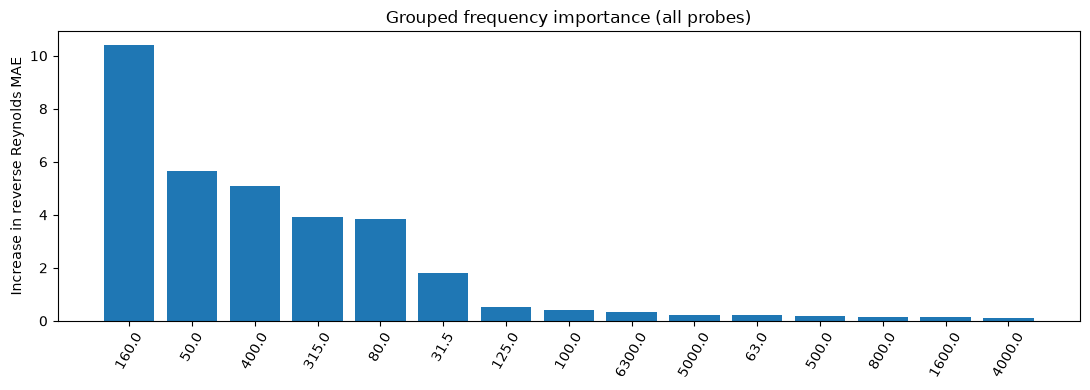

In [9]:
N_PERM=3; IMPORTANCE_SEED=123; rng=np.random.default_rng(IMPORTANCE_SEED)
# Limit expensive importance inference to evenly spaced held-out healthy endpoints.
# This subsample is used ONLY for permutation importance; all other analyses use all endpoints.
IMPORTANCE_MAX_WINDOWS=600
importance_idx=idx_val[np.unique(np.linspace(0,len(idx_val)-1,min(len(idx_val),IMPORTANCE_MAX_WINDOWS),dtype=int))]
# Block donor selection: use healthy windows, exclude nearby windows to avoid trivial replacements.
DONOR_MIN_SEPARATION=max(W,120)
def donor_indices(targets,eligible):
    picks=[]
    for t in targets:
        far=eligible[np.abs(eligible-t)>=DONOR_MIN_SEPARATION]
        if not len(far): raise ValueError('Insufficient separated healthy donor windows')
        picks.append(int(rng.choice(far)))
    return np.asarray(picks)
def permuted_mae(probe_idx,freq_idx):
    scores=[]
    for rep in range(N_PERM):
        donors=donor_indices(importance_idx,idx_val)
        donor_windows=np.stack([val['X'][t-W+1:t+1]/S_SCALE for t in donors]).astype(np.float32)
        lookup={int(t):j for j,t in enumerate(importance_idx)}
        def replace(x,ids):
            positions=np.asarray([lookup[int(t)] for t in ids])
            for p in probe_idx:
                for f in freq_idx: x[:,:,p,f]=donor_windows[positions,:,p,f]
            return x
        yhat=batch_predict_reverse(val,importance_idx,replace=replace)
        scores.append(mean_absolute_error(val['Re'][importance_idx],yhat))
    return np.mean(scores),np.std(scores,ddof=1) if N_PERM>1 else np.nan
baseline_mae=mean_absolute_error(val['Re'][importance_idx],batch_predict_reverse(val,importance_idx))
importance=[]
for f,frequency in enumerate(val['freqs']):
    mean,sd=permuted_mae(range(4),[f]); importance.append(dict(scope='all_probes',probe='ALL',frequency=frequency,MAE_permuted=mean,MAE_sd=sd,importance=mean-baseline_mae))
for p,probe in enumerate(PROBES):
    for f,frequency in enumerate(val['freqs']):
        mean,sd=permuted_mae([p],[f]); importance.append(dict(scope='probe_frequency',probe=probe,frequency=frequency,MAE_permuted=mean,MAE_sd=sd,importance=mean-baseline_mae))
importance=pd.DataFrame(importance).sort_values('importance',ascending=False)
importance.to_csv(OUT/'reverse_grouped_importance.csv',index=False)
display(importance.query("scope=='all_probes'").head(12));display(importance.query("scope=='probe_frequency'").head(12))
plt.figure(figsize=(11,4)); x=importance.query("scope=='all_probes'").sort_values('importance',ascending=False).head(15)
plt.bar(x['frequency'].astype(str),x['importance']);plt.xticks(rotation=60);plt.ylabel('Increase in reverse Reynolds MAE');plt.title('Grouped frequency importance (all probes)');plt.tight_layout();plt.savefig(OUT/'reverse_frequency_importance.png',dpi=160);plt.show()

## 2 — Forward signed bias × reverse importance

Per probe-frequency channel calculate mean signed residual (positive = forward **under**prediction; negative = **over**prediction), RMSE, correlation with Reynolds level, and difference in bias between ramp and stable windows. Join with reverse-model permutation importance. A high-importance/high-error channel is a priority for investigation, **not proof** that Reynolds causes its bias.

Healthy ramp windows: 3734 stable: 3833


,probe,frequency,n,mean_signed_residual,RMSE,corr_Re_signed_residual,bias_ramp,bias_stable,importance,abs_bias,ramp_minus_stable_bias
35,US,160.0,7567,0.799832,2.935800,0.144251,0.794138,0.805379,2.547912,0.799832,-0.011242
84,DDS,50.0,7567,-0.169239,3.161211,-0.006684,-0.098621,-0.238033,2.069898,0.169239,0.139413
30,US,50.0,7567,2.405956,5.226653,0.728883,2.533189,2.282010,1.819051,2.405956,0.251179
89,DDS,160.0,7567,-0.345330,2.413739,-0.199650,-0.238788,-0.449121,1.747495,0.345330,0.210333
32,US,80.0,7567,5.824451,6.717865,0.364393,6.067771,5.587417,1.321389,5.824451,0.480354
62,DS,160.0,7567,-2.503546,3.649545,-0.367481,-2.810158,-2.204853,1.197274,2.503546,-0.605305
39,US,400.0,7567,-0.799758,2.159455,-0.063661,-1.023427,-0.581866,0.914361,0.799758,-0.441561
8,UUS,160.0,7567,-0.204328,1.942518,-0.200883,-0.337799,-0.074306,0.913617,0.204328,-0.263493
28,US,31.5,7567,3.765194,5.142095,0.386857,4.445514,3.102445,0.882718,3.765194,1.343069
38,US,315.0,7567,-1.358158,3.122196,0.096521,-1.834797,-0.893830,0.715603,1.358158,-0.940966


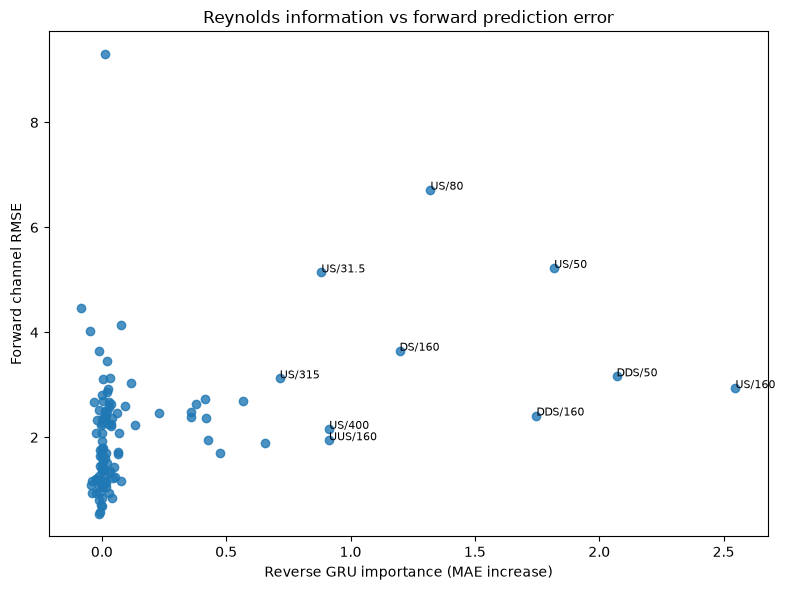

In [10]:
# Define ramp using Reynolds difference across the 40-step history, not leak-filtered neighboring endpoints.
RAMP_THRESHOLD=0.02 # Reynolds units per second: adjust based on sampling and physical ramp sizes
smooth_delta=np.abs(np.diff(val['Re'],prepend=val['Re'][0]));
# 15-second smoothed absolute derivative, ending at each endpoint
ramp_strength=pd.Series(smooth_delta).rolling(15,min_periods=1).mean().to_numpy()
is_ramp=ramp_strength[idx_val]>RAMP_THRESHOLD
print('Healthy ramp windows:',is_ramp.sum(),'stable:',(~is_ramp).sum())
rows=[]
for p,probe in enumerate(PROBES):
    for f,frequency in enumerate(val['freqs']):
        err=residual[:,p,f]
        rows.append(dict(probe=probe,frequency=frequency,n=len(err),mean_signed_residual=err.mean(),RMSE=np.sqrt(np.mean(err**2)),corr_Re_signed_residual=np.corrcoef(y_re,err)[0,1] if np.std(err)>0 else np.nan,
                         bias_ramp=err[is_ramp].mean() if is_ramp.any() else np.nan,
                         bias_stable=err[~is_ramp].mean() if (~is_ramp).any() else np.nan))
channels=pd.DataFrame(rows)
joined=channels.merge(importance.query("scope=='probe_frequency'")[['probe','frequency','importance']],on=['probe','frequency'],validate='one_to_one')
joined['abs_bias']=joined['mean_signed_residual'].abs()
joined['ramp_minus_stable_bias']=joined['bias_ramp']-joined['bias_stable']
joined.to_csv(OUT/'cross_model_channel_diagnostics.csv',index=False)
display(joined.sort_values('importance',ascending=False).head(20))
plt.figure(figsize=(8,6));plt.scatter(joined['importance'],joined['RMSE'],alpha=.8)
for _,r in joined.nlargest(10,'importance').iterrows():plt.annotate(f"{r['probe']}/{r['frequency']:g}",(r['importance'],r['RMSE']),fontsize=8)
plt.xlabel('Reverse GRU importance (MAE increase)');plt.ylabel('Forward channel RMSE');plt.title('Reynolds information vs forward prediction error');plt.tight_layout();plt.savefig(OUT/'importance_vs_forward_error.png',dpi=160);plt.show()

## 3 — Bidirectional consistency on complete reconstructed histories

For each healthy endpoint, use the reverse GRU twice: (a) its original **observed** 40-step spectral history; (b) a 40-step history of spectra generated by the forward model. Crucially, generating each predicted spectral history requires running the forward LSTM with Reynolds histories ending at **each of the 40 time points**, which in turn requires 39 extra earlier Reynolds samples. We exclude endpoints before index `2W−2` and require healthy history over all `2W−1` points. This avoids the common error of feeding a single endpoint spectrum 40 times.

Compare reverse MAE on observed vs forward-reconstructed spectra, and `G(F(Re))−G(observed spectra)`; this is a **diagnostic of retained Reynolds information**, not a guarantee of physically correct spectra.

Reverse MAE on observed spectra: 9.898904800415039
Reverse MAE on forward spectra: 4.79957914352417
Mean absolute disagreement: 8.778202


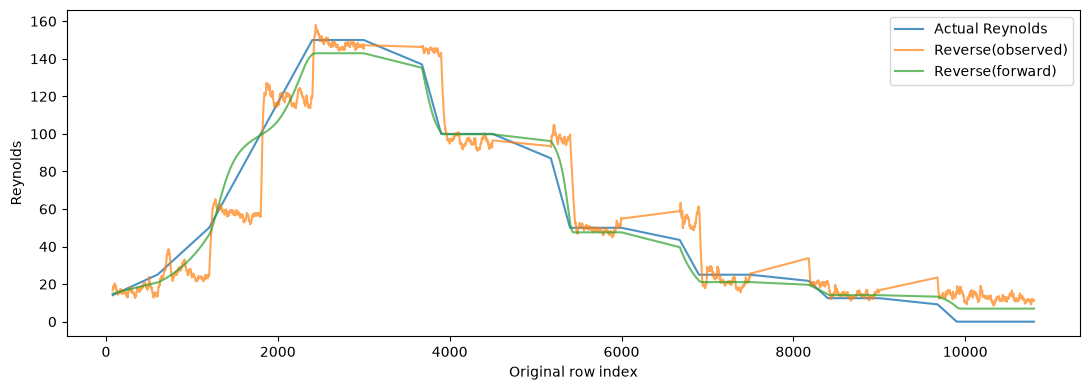

In [11]:
# The forward LSTM is causal in Reynolds history and probe coordinates.
# Its prediction at time t can be obtained from a single 40-step forward call ending at t.
# Build a dense predicted sequence for all t >= W-1, and retain only endpoints with
# a complete healthy 2W-1 observation history.
valid_cycle=np.arange(2*W-2,len(val['Re']))
healthy_long=np.convolve((val['leak']!=0).astype(int),np.ones(2*W-1,dtype=int),'valid')
valid_cycle=valid_cycle[healthy_long==0]
if not len(valid_cycle): raise ValueError('No healthy 79-step histories for cycle test')
needed=np.unique(np.concatenate([np.arange(t-W+1,t+1) for t in valid_cycle]))
forward_dense=batch_predict_forward(val,needed)
# map full original row index to forward endpoint predictions
pred_at={int(t):forward_dense[j] for j,t in enumerate(needed)}
cycle_observed=batch_predict_reverse(val,valid_cycle)
def predict_reverse_from_reconstructed(indices,batch=256):
    output=[]
    with torch.no_grad():
        for start in range(0,len(indices),batch):
            ids=indices[start:start+batch]
            histories=np.stack([[pred_at[k] for k in range(t-W+1,t+1)] for t in ids]).astype(np.float32)/S_SCALE
            output.append(reverse(torch.from_numpy(histories).to(DEVICE)).cpu().numpy()*RE_SCALE)
    return np.concatenate(output)
cycle_reconstructed=predict_reverse_from_reconstructed(valid_cycle)
cycle=pd.DataFrame({'endpoint_index':valid_cycle,'Re_actual':val['Re'][valid_cycle], 'Re_from_actual_spectra':cycle_observed,'Re_from_forward_spectra':cycle_reconstructed})
cycle['reverse_difference']=cycle['Re_from_forward_spectra']-cycle['Re_from_actual_spectra']
cycle.to_csv(OUT/'bidirectional_cycle_consistency.csv',index=False)
print('Reverse MAE on observed spectra:',mean_absolute_error(cycle.Re_actual,cycle.Re_from_actual_spectra))
print('Reverse MAE on forward spectra:',mean_absolute_error(cycle.Re_actual,cycle.Re_from_forward_spectra))
print('Mean absolute disagreement:',cycle.reverse_difference.abs().mean())
plt.figure(figsize=(11,4));plt.plot(cycle.endpoint_index,cycle.Re_actual,label='Actual Reynolds',alpha=.8);plt.plot(cycle.endpoint_index,cycle.Re_from_actual_spectra,label='Reverse(observed)',alpha=.7);plt.plot(cycle.endpoint_index,cycle.Re_from_forward_spectra,label='Reverse(forward)',alpha=.7)
plt.legend();plt.xlabel('Original row index');plt.ylabel('Reynolds');plt.tight_layout();plt.savefig(OUT/'bidirectional_cycle.png',dpi=160);plt.show()

## 4 — Does Reynolds history help forward prediction?

Train two **Ridge benchmark** models using healthy `1211_1` windows, evaluate on healthy `1212_1` windows, without changing existing `.pt` checkpoints:

- **Current Re + probe coordinates:** predicts each of 108 amplitudes from `Re_t` (probe identity is implicit in the output channel).
- **40-step Re history:** predicts the same 108 amplitudes from `Re_{t−39:t}`.

Both models see the same endpoints and targets. This comparison tests whether Reynolds history improves forward predictive accuracy for a simple linear model; it does not prove that a nonlinear LSTM does/does not need history. Evaluate separately during ramps and stable regimes and inspect signed biases. Run-level split limits overlap leakage, but `1212_1` was previously used for model selection, so results remain exploratory until a new untouched run is used.

,model,regime,n,RMSE,MAE,mean_signed_residual
0,current_Re,all,7567,4.494086,3.118409,-0.064488
1,current_Re,ramp,3734,4.556412,3.168709,-0.173771
2,current_Re,stable,3833,4.432527,3.069407,0.041973
3,history_40,all,7567,4.476352,3.105830,-0.064541
4,history_40,ramp,3734,4.514720,3.135236,-0.175973
5,history_40,stable,3833,4.438656,3.077184,0.044012


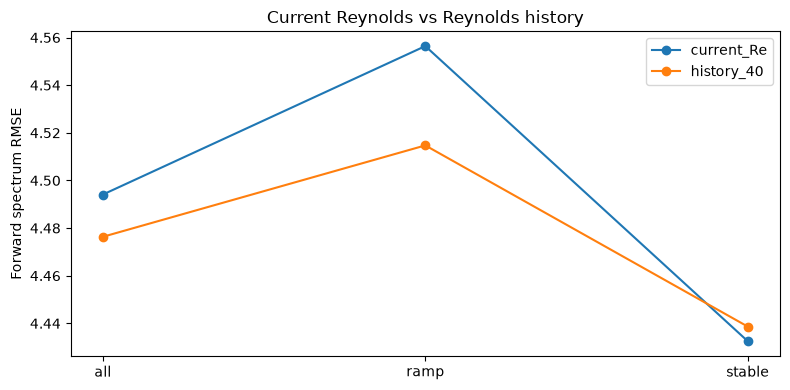

In [12]:
def make_features(run,indices,history):
    if history: return np.stack([run['Re'][t-W+1:t+1] for t in indices]).astype(float)
    return run['Re'][indices,None].astype(float)
Y_train=train['X'][idx_train].reshape(len(idx_train),-1)
Y_eval=val['X'][idx_val].reshape(len(idx_val),-1)
benchmark=[]; preds={}
for label,history in [('current_Re',False),('history_40',True)]:
    model=make_pipeline(StandardScaler(),Ridge(alpha=100.0))
    model.fit(make_features(train,idx_train,history),Y_train)
    yp=model.predict(make_features(val,idx_val,history)).reshape(-1,4,27)
    preds[label]=yp
    for regime,mask in [('all',np.ones(len(idx_val),bool)),('ramp',is_ramp),('stable',~is_ramp)]:
        if not mask.any():continue
        e=actual[mask]-yp[mask]
        benchmark.append(dict(model=label,regime=regime,n=int(mask.sum()),RMSE=float(np.sqrt(np.mean(e**2))),MAE=float(np.mean(np.abs(e))),mean_signed_residual=float(e.mean())))
bench=pd.DataFrame(benchmark);bench.to_csv(OUT/'current_vs_history_benchmark.csv',index=False);display(bench)
perchannel=[]
for label,yp in preds.items():
    e=actual-yp
    for p,probe in enumerate(PROBES):
        for f,frequency in enumerate(val['freqs']):
            perchannel.append(dict(model=label,probe=probe,frequency=frequency,RMSE=np.sqrt(np.mean(e[:,p,f]**2)),bias=e[:,p,f].mean(),RMSE_ramp=np.sqrt(np.mean(e[is_ramp,p,f]**2)) if is_ramp.any() else np.nan,RMSE_stable=np.sqrt(np.mean(e[~is_ramp,p,f]**2)) if (~is_ramp).any() else np.nan))
pd.DataFrame(perchannel).to_csv(OUT/'current_vs_history_by_channel.csv',index=False)
plt.figure(figsize=(8,4));
for name,g in bench.groupby('model'):
    plt.plot(g['regime'],g['RMSE'],'o-',label=name)
plt.ylabel('Forward spectrum RMSE');plt.title('Current Reynolds vs Reynolds history');plt.legend();plt.tight_layout();plt.savefig(OUT/'current_vs_history.png',dpi=160);plt.show()

## Final synthesis and guardrails

The tables below provide the evidence for the four recommended analyses. **Do not interpret permutation importance, cycle consistency, or ramp/stable differences as causal effects.** Bias signs must be interpreted as `actual − predicted`.

For a stronger generalization claim, repeat on a **new untouched run** with compatible coordinates and leak labels. For causal identification, additional independent flow interventions or defensible controls are needed. Reverse importance cannot establish that Reynolds uniquely determines spectra.

In [13]:
top=importance.query("scope=='all_probes'").nlargest(5,'importance')
print('Top five reverse-predictive frequencies:');display(top[['frequency','importance','MAE_sd']])
print('Highest reverse-importance probe/frequency channels with forward errors:')
display(joined.nlargest(10,'importance')[['probe','frequency','importance','mean_signed_residual','RMSE','corr_Re_signed_residual','ramp_minus_stable_bias']])
print('Bidirectional MAE observed:',round(mean_absolute_error(cycle.Re_actual,cycle.Re_from_actual_spectra),4),'forward:',round(mean_absolute_error(cycle.Re_actual,cycle.Re_from_forward_spectra),4))
display(bench)
summary={'reverse_checkpoint':str(reverse_path),'forward_checkpoint':str(forward_path),'train_run':TRAIN_RUN,'eval_run':EVAL_RUN,'healthy_eval_windows':int(len(idx_val)),'cycle_windows':int(len(valid_cycle)),'reverse_baseline_mae':float(baseline_mae),'reverse_cycle_actual_mae':float(mean_absolute_error(cycle.Re_actual,cycle.Re_from_actual_spectra)),'reverse_cycle_forward_mae':float(mean_absolute_error(cycle.Re_actual,cycle.Re_from_forward_spectra)),'ramp_threshold':RAMP_THRESHOLD,'caution':'Observational predictive diagnostics, not causal identification'}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
print('All outputs:',OUT)

Top five reverse-predictive frequencies:


,frequency,importance,MAE_sd
8,160.0,10.402256,0.150910
3,50.0,5.661891,0.328048
12,400.0,5.094182,0.407819
11,315.0,3.937253,0.310494
5,80.0,3.858181,0.308830


Highest reverse-importance probe/frequency channels with forward errors:


,probe,frequency,importance,mean_signed_residual,RMSE,corr_Re_signed_residual,ramp_minus_stable_bias
35,US,160.0,2.547912,0.799832,2.935800,0.144251,-0.011242
84,DDS,50.0,2.069898,-0.169239,3.161211,-0.006684,0.139413
30,US,50.0,1.819051,2.405956,5.226653,0.728883,0.251179
89,DDS,160.0,1.747495,-0.345330,2.413739,-0.199650,0.210333
32,US,80.0,1.321389,5.824451,6.717865,0.364393,0.480354
62,DS,160.0,1.197274,-2.503546,3.649545,-0.367481,-0.605305
39,US,400.0,0.914361,-0.799758,2.159455,-0.063661,-0.441561
8,UUS,160.0,0.913617,-0.204328,1.942518,-0.200883,-0.263493
28,US,31.5,0.882718,3.765194,5.142095,0.386857,1.343069
38,US,315.0,0.715603,-1.358158,3.122196,0.096521,-0.940966


Bidirectional MAE observed: 9.8989 forward: 4.7996


,model,regime,n,RMSE,MAE,mean_signed_residual
0,current_Re,all,7567,4.494086,3.118409,-0.064488
1,current_Re,ramp,3734,4.556412,3.168709,-0.173771
2,current_Re,stable,3833,4.432527,3.069407,0.041973
3,history_40,all,7567,4.476352,3.105830,-0.064541
4,history_40,ramp,3734,4.514720,3.135236,-0.175973
5,history_40,stable,3833,4.438656,3.077184,0.044012


All outputs: /home/ubuntu/notebooks/Leak_Detection/results/bidirectional_reynolds
